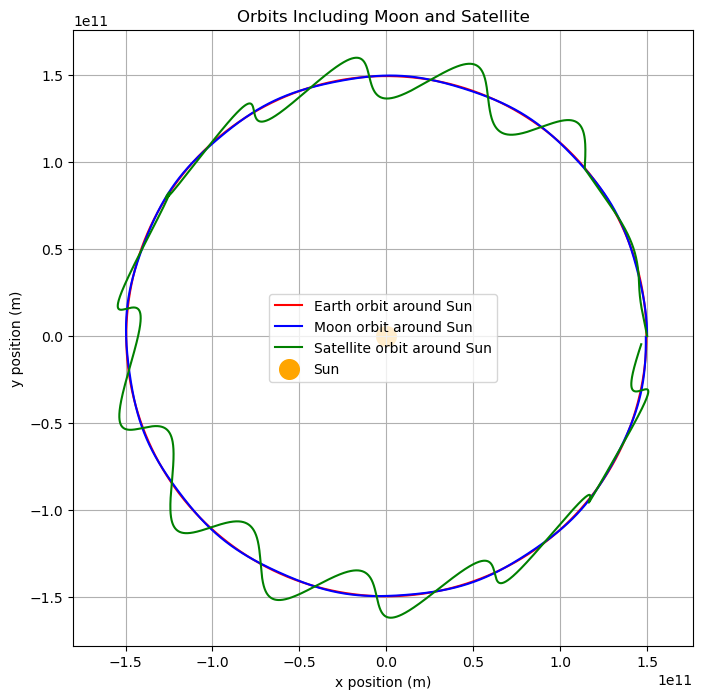

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
G = 6.67430e-11  # Gravitational constant (m^3 kg^-1 s^-2)
M_sun = 1.989e30  # Mass of the Sun (kg)
M_earth = 5.972e24  # Mass of the Earth (kg)
M_moon = 7.348e22  # Mass of the Moon (kg)
M_satellite = 3000  # Mass of the satellite (kg)

# Distances
R_earth_sun = 1.496e11  # Distance between Earth and Sun (m)
R_moon_earth = 3.844e8  # Distance between Moon and Earth (m)
R_satellite_moon = 1.737e6  # Distance between Satellite and Moon (m)

# Orbital velocities (assuming circular orbits)
V_earth_sun = np.sqrt(G * M_sun / R_earth_sun)
V_moon_earth = np.sqrt(G * M_earth / R_moon_earth)
V_satellite_moon = np.sqrt(G * M_moon / R_satellite_moon)

# Time settings
dt = 3600  # Time step in seconds (1 hour)
total_time = 365 * 24 * 3600  # One year in seconds
num_steps = total_time // dt

# Initialize positions and velocities
x_e, y_e = [R_earth_sun], [0]
vx_e, vy_e = [0], [V_earth_sun]

x_m, y_m = [R_earth_sun + R_moon_earth], [0]
vx_m, vy_m = [0], [V_earth_sun + V_moon_earth]

x_s, y_s = [R_earth_sun + R_moon_earth + R_satellite_moon], [0]
vx_s, vy_s = [0], [V_earth_sun + V_moon_earth + V_satellite_moon]

# Simulation loop
for _ in range(int(num_steps)):
    # Compute accelerations
    r_e = np.sqrt(x_e[-1]**2 + y_e[-1]**2)
    r_m = np.sqrt((x_m[-1] - x_e[-1])**2 + (y_m[-1] - y_e[-1])**2)
    r_s = np.sqrt((x_s[-1] - x_m[-1])**2 + (y_s[-1] - y_m[-1])**2)

    ax_e = -G * M_sun * x_e[-1] / r_e**3
    ay_e = -G * M_sun * y_e[-1] / r_e**3

    ax_m = -G * M_earth * (x_m[-1] - x_e[-1]) / r_m**3 - G * M_sun * x_m[-1] / r_e**3
    ay_m = -G * M_earth * (y_m[-1] - y_e[-1]) / r_m**3 - G * M_sun * y_m[-1] / r_e**3

    ax_s = -G * M_moon * (x_s[-1] - x_m[-1]) / r_s**3 - G * M_earth * (x_s[-1] - x_e[-1]) / r_m**3 - G * M_sun * x_s[-1] / r_e**3
    ay_s = -G * M_moon * (y_s[-1] - y_m[-1]) / r_s**3 - G * M_earth * (y_s[-1] - y_e[-1]) / r_m**3 - G * M_sun * y_s[-1] / r_e**3

    # Update velocities
    vx_e.append(vx_e[-1] + ax_e * dt)
    vy_e.append(vy_e[-1] + ay_e * dt)

    vx_m.append(vx_m[-1] + ax_m * dt)
    vy_m.append(vy_m[-1] + ay_m * dt)

    vx_s.append(vx_s[-1] + ax_s * dt)
    vy_s.append(vy_s[-1] + ay_s * dt)

    # Update positions
    x_e.append(x_e[-1] + vx_e[-1] * dt)
    y_e.append(y_e[-1] + vy_e[-1] * dt)

    x_m.append(x_m[-1] + vx_m[-1] * dt)
    y_m.append(y_m[-1] + vy_m[-1] * dt)

    x_s.append(x_s[-1] + vx_s[-1] * dt)
    y_s.append(y_s[-1] + vy_s[-1] * dt)

# Plot results
plt.figure(figsize=(8, 8))
plt.plot(x_e, y_e, 'r-', label='Earth orbit around Sun')
plt.plot(x_m, y_m, 'b-', label='Moon orbit around Sun')
plt.plot(x_s, y_s, 'g-', label='Satellite orbit around Sun')
plt.scatter(0, 0, color='orange', s=200, label='Sun')
plt.legend()
plt.xlabel('x position (m)')
plt.ylabel('y position (m)')
plt.title('Orbits Including Moon and Satellite')
plt.axis('equal')
plt.grid()
plt.show()


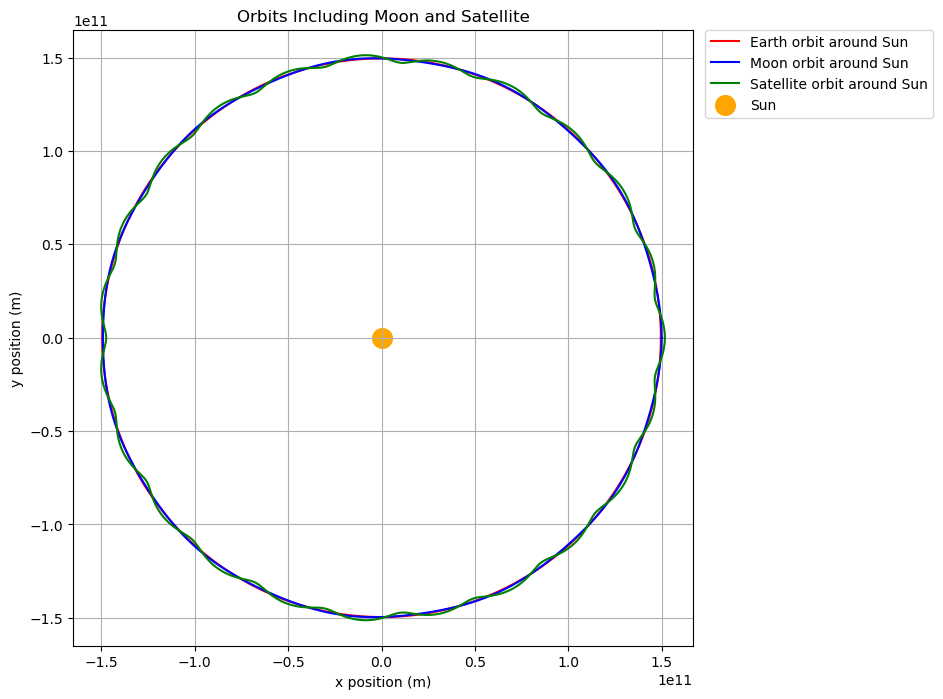

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
G = 6.67430e-11  # Gravitational constant (m^3 kg^-1 s^-2)
M_sun = 1.989e30  # Mass of the Sun (kg)
M_earth = 5.972e24  # Mass of the Earth (kg)
M_moon = 7.348e22  # Mass of the Moon (kg)
M_satellite = 1000  # Mass of the satellite (kg)

# Distances
R_earth_sun = 1.496e11  # Distance between Earth and Sun (m)
R_moon_earth = 3.844e8  # Distance between Moon and Earth (m)
R_satellite_moon = 1.737e9 + 2.0e5  # Distance between Satellite and Moon (m)

# User-defined initial velocities
V_earth_sun = np.sqrt(G * M_sun / R_earth_sun)
V_moon_earth = np.sqrt(G * M_earth / R_moon_earth)
V_satellite_moon = np.sqrt(G * M_moon / R_satellite_moon)

# Time settings
dt = 3600  # Time step in seconds (1 hour)
total_time = 365 * 24 * 3600  # One year in seconds
num_steps = total_time // dt

# Initialize positions and velocities
x_e, y_e = [R_earth_sun], [0]
vx_e, vy_e = [0], [V_earth_sun]

x_m, y_m = [R_earth_sun + R_moon_earth], [0]
vx_m, vy_m = [0], [V_earth_sun + V_moon_earth]

x_s, y_s = [R_earth_sun + R_moon_earth + R_satellite_moon], [0]
vx_s, vy_s = [0], [V_earth_sun + V_moon_earth + V_satellite_moon]

# Circular motion simulation loop
for i in range(int(num_steps)):
    angle_e = 2 * np.pi * i / num_steps
    x_e.append(R_earth_sun * np.cos(angle_e))
    y_e.append(R_earth_sun * np.sin(angle_e))

    angle_m = 2 * np.pi * i / (num_steps / 12)
    x_m.append(x_e[-1] + R_moon_earth * np.cos(angle_m))
    y_m.append(y_e[-1] + R_moon_earth * np.sin(angle_m))

    angle_s = 2 * np.pi * i / (num_steps / 24)
    x_s.append(x_m[-1] + R_satellite_moon * np.cos(angle_s))
    y_s.append(y_m[-1] + R_satellite_moon * np.sin(angle_s))

# Plot results
plt.figure(figsize=(8, 8))
plt.plot(x_e, y_e, 'r-', label='Earth orbit around Sun')
plt.plot(x_m, y_m, 'b-', label='Moon orbit around Sun')
plt.plot(x_s, y_s, 'g-', label='Satellite orbit around Sun')
plt.scatter(0, 0, color='orange', s=200, label='Sun')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.xlabel('x position (m)')
plt.ylabel('y position (m)')
plt.title('Orbits Including Moon and Satellite')
plt.axis('equal')
plt.grid()
plt.show()
